In [1]:
import sys
import inspect

sys.path.append("..")

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    log_loss,
    brier_score_loss
)

from src.logreg import (
    fitScaling,
    applyScaling,
    fitLogreg,
    predictLogreg
)

from src.evaluate import resultsRow, calibration

loading datset

In [2]:
Shots = pd.read_parquet("../data/features/shots_features.parquet")

print("Total shots:", len(Shots))
print("Total columns:", len(Shots.columns))

print("\nTrain/test split:")
print(Shots["test"].value_counts())

print("\nValidation folds:")
print(Shots.groupby(["test", "fold"]).size())

Total shots: 99746
Total columns: 49

Train/test split:
test
False    74944
True     24802
Name: count, dtype: int64

Validation folds:
test   fold
False  1       15047
       2       14992
       3       15056
       4       14943
       5       14906
True   0       24802
dtype: int64


selectuibg our training and valodatinf data

In [3]:
TrainShots = Shots[
    (Shots["test"] == False) & (Shots["fold"] != 1)
].copy()

ValidShots = Shots[
    (Shots["test"] == False) & (Shots["fold"] == 1)
].copy()

print("Training shots:", len(TrainShots))
print("Validation shots:", len(ValidShots))

print("Training goal rate:", round(TrainShots["goal"].mean() * 100, 2), "%")
print("Validation goal rate:", round(ValidShots["goal"].mean() * 100, 2), "%")

print(
    "Matches shared between training and validation:",
    len(set(TrainShots["match_id"]) & set(ValidShots["match_id"]))
)

Training shots: 59897
Validation shots: 15047
Training goal rate: 10.15 %
Validation goal rate: 10.59 %
Matches shared between training and validation: 0


In [4]:
FeatureNames = ["distance", "angle"]

XTrain = TrainShots[FeatureNames].to_numpy(dtype=float)
YTrain = TrainShots["goal"].to_numpy(dtype=int)

XValid = ValidShots[FeatureNames].to_numpy(dtype=float)
YValid = ValidShots["goal"].to_numpy(dtype=int)

print("Training features:", XTrain.shape)
print("Validation features:", XValid.shape)

print("Missing training values:", np.isnan(XTrain).sum())
print("Missing validation values:", np.isnan(XValid).sum())

Training features: (59897, 2)
Validation features: (15047, 2)
Missing training values: 0
Missing validation values: 0


In [5]:
Mean, Std = fitScaling(XTrain)

XTrainScaled = applyScaling(XTrain, Mean, Std)
XValidScaled = applyScaling(XValid, Mean, Std)

print("Training mean:", np.mean(XTrainScaled, axis=0))
print("Training std:", np.std(XTrainScaled, axis=0))

print("Validation shape:", XValidScaled.shape)

print("Missing training values:", np.isnan(XTrainScaled).sum())
print("Missing validation values:", np.isnan(XValidScaled).sum())

Training mean: [-1.59435270e-16  3.32156813e-17]
Training std: [1. 1.]
Validation shape: (15047, 2)
Missing training values: 0
Missing validation values: 0


trainng our leg reg model 

In [6]:
Weights = fitLogreg(
    XTrainScaled,
    YTrain,
    rate=0.1,
    steps=2000
)

TrainProbabilities = predictLogreg(Weights, XTrainScaled)
ValidProbabilities = predictLogreg(Weights, XValidScaled)

TrainAUC = roc_auc_score(YTrain, TrainProbabilities)
ValidAUC = roc_auc_score(YValid, ValidProbabilities)

print("Weights:", Weights)
print("Training AUC:", round(TrainAUC, 4))
print("Validation AUC:", round(ValidAUC, 4))

Weights: [-2.48087962 -0.59676918  0.34491091]
Training AUC: 0.7409
Validation AUC: 0.7436


comparing againsr scikit learn 

In [7]:
SklearnModel = LogisticRegression(
    max_iter=2000,
    C=1000000
)

SklearnModel.fit(XTrainScaled, YTrain)

SklearnProbabilities = SklearnModel.predict_proba(XValidScaled)[:, 1]

SklearnAUC = roc_auc_score(YValid, SklearnProbabilities)

print("NumPy validation AUC:", round(ValidAUC, 4))
print("Sklearn validation AUC:", round(SklearnAUC, 4))
print("AUC difference:", round(abs(ValidAUC - SklearnAUC), 6))
print("Within 0.005:", abs(ValidAUC - SklearnAUC) <= 0.005)

NumPy validation AUC: 0.7436
Sklearn validation AUC: 0.7436
AUC difference: 2.6e-05
Within 0.005: True


In [8]:
print("NumPy weights:", Weights[1:])
print("Sklearn weights:", SklearnModel.coef_[0])

print("NumPy bias:", Weights[0])
print("Sklearn bias:", SklearnModel.intercept_[0])

print(
    "Maximum weight difference:",
    np.max(np.abs(Weights[1:] - SklearnModel.coef_[0]))
)

NumPy weights: [-0.59676918  0.34491091]
Sklearn weights: [-0.61378578  0.33566344]
NumPy bias: -2.4808796156316766
Sklearn bias: -2.486249973196486
Maximum weight difference: 0.017016594051172174


In [9]:
FlagColumns = [
    "under_pressure",
    "shot_first_time",
    "shot_one_on_one",
    "shot_open_goal",
    "shot_aerial_won",
    "shot_follows_dribble",
    "shot_redirect"
]

print("Total dataset columns:", len(Shots.columns))
print("Missing flags:", [
    Column for Column in FlagColumns
    if Column not in Shots.columns
])

Total dataset columns: 49
Missing flags: []


preping full feat log reg

In [10]:
ExcludeColumns = ["id", "match_id", "test", "fold", "goal", "x", "y"]

AllFeatures = [
    Column for Column in Shots.columns
    if Column not in ExcludeColumns
]

print("Total dataset columns:", len(Shots.columns))
print("Total modeling features:", len(AllFeatures))
print("Missing flags:", [
    Column for Column in FlagColumns
    if Column not in AllFeatures
])

Total dataset columns: 49
Total modeling features: 42
Missing flags: []


In [11]:
TrainMedians = TrainShots[AllFeatures].median()

XTrainFull = TrainShots[AllFeatures].fillna(TrainMedians).to_numpy(dtype=float)
XValidFull = ValidShots[AllFeatures].fillna(TrainMedians).to_numpy(dtype=float)

print("Training shape:", XTrainFull.shape)
print("Validation shape:", XValidFull.shape)

print("Missing training values:", np.isnan(XTrainFull).sum())
print("Missing validation values:", np.isnan(XValidFull).sum())

Training shape: (59897, 42)
Validation shape: (15047, 42)
Missing training values: 0
Missing validation values: 0


std all feat 35

In [12]:
FullMean, FullStd = fitScaling(XTrainFull)

XTrainFullScaled = applyScaling(XTrainFull, FullMean, FullStd)
XValidFullScaled = applyScaling(XValidFull, FullMean, FullStd)

print("Training shape:", XTrainFullScaled.shape)
print("Validation shape:", XValidFullScaled.shape)
print("Missing training values:", np.isnan(XTrainFullScaled).sum())
print("Missing validation values:", np.isnan(XValidFullScaled).sum())
print("Training means:", np.round(np.mean(XTrainFullScaled, axis=0)[:5], 4))
print("Training std:", np.round(np.std(XTrainFullScaled, axis=0)[:5], 4))

Training shape: (59897, 42)
Validation shape: (15047, 42)
Missing training values: 0
Missing validation values: 0
Training means: [-0.  0.  0. -0. -0.]
Training std: [1. 1. 1. 1. 1.]


traing the full feature log reg model

In [13]:
FullWeights = fitLogreg(
    XTrainFullScaled,
    YTrain,
    rate=0.1,
    steps=2000
)
FullTrainProbabilities = predictLogreg(
    FullWeights,
    XTrainFullScaled
)
FullValidProbabilities = predictLogreg(
    FullWeights,
    XValidFullScaled
)
FullTrainAUC = roc_auc_score(YTrain, FullTrainProbabilities)
FullValidAUC = roc_auc_score(YValid, FullValidProbabilities)

print("Number of weights:", len(FullWeights))
print("Training AUC:", round(FullTrainAUC, 4))
print("Validation AUC:", round(FullValidAUC, 4))
print("Basic model AUC:", round(ValidAUC, 4))
print("Improvement:", round(FullValidAUC - ValidAUC, 4))

Number of weights: 43
Training AUC: 0.8015
Validation AUC: 0.8088
Basic model AUC: 0.7436
Improvement: 0.0652


trsing the XGBoost baseline

In [14]:
from xgboost import XGBClassifier
XGBModel = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
XGBModel.fit(XTrainFull, YTrain)

XGBTrainProbabilities = XGBModel.predict_proba(XTrainFull)[:, 1]
XGBValidProbabilities = XGBModel.predict_proba(XValidFull)[:, 1]

XGBTrainAUC = roc_auc_score(YTrain, XGBTrainProbabilities)
XGBValidAUC = roc_auc_score(YValid, XGBValidProbabilities)

print("XGBoost training AUC:", round(XGBTrainAUC, 4))
print("XGBoost validation AUC:", round(XGBValidAUC, 4))
print("Full logistic regression AUC:", round(FullValidAUC, 4))
print("XGBoost improvement:", round(XGBValidAUC - FullValidAUC, 4))

XGBoost training AUC: 0.824
XGBoost validation AUC: 0.8131
Full logistic regression AUC: 0.8088
XGBoost improvement: 0.0043


In [15]:
FeatureImportance = pd.Series(
    XGBModel.feature_importances_,
    index=AllFeatures
)

FeatureImportance = FeatureImportance.sort_values(ascending=False)

print("Top 10 features:")
print(FeatureImportance.head(10))

print("\nshot_open_goal importance:", FeatureImportance["shot_open_goal"])
print("shot_open_goal rank:", FeatureImportance.index.get_loc("shot_open_goal") + 1)

Top 10 features:
shot_open_goal              0.169821
keeperToShooter             0.136786
keeperInCone                0.094604
shot_aerial_won             0.068311
shot_body_part_Head         0.058584
angle                       0.056421
defendersInCone             0.048789
shot_type_Open Play         0.035940
shot_type_Corner            0.031311
play_pattern_From Corner    0.025902
dtype: float32

shot_open_goal importance: 0.16982053
shot_open_goal rank: 1


In [16]:
from sklearn.metrics import log_loss

TuningResults = []

for Depth in [3, 5]:
    for ChildWeight in [1, 10]:
        Model = XGBClassifier(
            n_estimators=400,
            max_depth=Depth,
            min_child_weight=ChildWeight,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        Model.fit(XTrainFull, YTrain)

        Probabilities = Model.predict_proba(XValidFull)[:, 1]
        ValidLogLoss = log_loss(YValid, Probabilities)

        TuningResults.append({
            "max_depth": Depth,
            "min_child_weight": ChildWeight,
            "log_loss": ValidLogLoss
        })

TuningResults = pd.DataFrame(TuningResults)
TuningResults = TuningResults.sort_values("log_loss")

print(TuningResults.to_string(index=False))

 max_depth  min_child_weight  log_loss
         3                 1  0.266870
         3                10  0.266942
         5                 1  0.267660
         5                10  0.268077


In [17]:
print("Training and validation shots:", len(Shots[Shots["test"] == False]))
print("Locked test shots:", len(Shots[Shots["test"] == True]))
print("Modeling features:", len(AllFeatures))

print("Validation folds:", sorted(Shots.loc[~Shots["test"], "fold"].unique()))
print("Test excluded from validation folds:", (Shots.loc[~Shots["test"], "fold"] != 0).all())

Training and validation shots: 74944
Locked test shots: 24802
Modeling features: 42
Validation folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Test excluded from validation folds: True


In [18]:
TuningResultsCV = []

for Depth in [3, 5]:
    for ChildWeight in [1, 10]:
        FoldLosses = []
        for Fold in range(1, 6):
            FoldTrain = Shots[
                (~Shots["test"]) & (Shots["fold"] != Fold)
            ]

            FoldValid = Shots[
                (~Shots["test"]) & (Shots["fold"] == Fold)
            ]
            FoldMedians = FoldTrain[AllFeatures].median()
            FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
            FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
            FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)
            FoldYValid = FoldValid["goal"].to_numpy(dtype=int)

            FoldModel = XGBClassifier(
                n_estimators=400,
                max_depth=Depth,
                min_child_weight=ChildWeight,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=5,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
            FoldModel.fit(FoldXTrain, FoldYTrain)
            FoldProbabilities = FoldModel.predict_proba(FoldXValid)[:, 1]
            FoldLoss = log_loss(FoldYValid, FoldProbabilities)
            FoldLosses.append(FoldLoss)
        MeanLoss = np.mean(FoldLosses)
        TuningResultsCV.append({
            "max_depth": Depth,
            "min_child_weight": ChildWeight,
            "mean_log_loss": MeanLoss
        })
        print(
            "Depth:", Depth,
            "| Child weight:", ChildWeight,
            "| Mean log loss:", round(MeanLoss, 6)
        )

TuningResultsCV = pd.DataFrame(TuningResultsCV)
TuningResultsCV = TuningResultsCV.sort_values("mean_log_loss")

print("\nFive-fold tuning results:")
print(TuningResultsCV.to_string(index=False))

Depth: 3 | Child weight: 1 | Mean log loss: 0.262286
Depth: 3 | Child weight: 10 | Mean log loss: 0.262415
Depth: 5 | Child weight: 1 | Mean log loss: 0.262873
Depth: 5 | Child weight: 10 | Mean log loss: 0.262944

Five-fold tuning results:
 max_depth  min_child_weight  mean_log_loss
         3                 1       0.262286
         3                10       0.262415
         5                 1       0.262873
         5                10       0.262944


In [19]:
BestSettings = TuningResultsCV.iloc[0]

BestDepth = int(BestSettings["max_depth"])
BestChildWeight = int(BestSettings["min_child_weight"])

print("Selected max depth:", BestDepth)
print("Selected min child weight:", BestChildWeight)
print("Cross-validation log loss:", round(BestSettings["mean_log_loss"], 6))

Selected max depth: 3
Selected min child weight: 1
Cross-validation log loss: 0.262286


In [20]:
XGBOOF = pd.Series(np.nan, index=Shots.index, dtype=float)

for Fold in range(1, 6):
    FoldTrain = Shots[
        (~Shots["test"]) & (Shots["fold"] != Fold)
    ]

    FoldValid = Shots[
        (~Shots["test"]) & (Shots["fold"] == Fold)
    ]

    FoldMedians = FoldTrain[AllFeatures].median()

    FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)

    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)

    FoldModel = XGBClassifier(
        n_estimators=400,
        max_depth=BestDepth,
        min_child_weight=BestChildWeight,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    FoldModel.fit(FoldXTrain, FoldYTrain)

    FoldProbabilities = FoldModel.predict_proba(FoldXValid)[:, 1]

    XGBOOF.loc[FoldValid.index] = FoldProbabilities

    print("Fold:", Fold, "| Predictions:", len(FoldProbabilities))

print("OOF predictions:", XGBOOF.notna().sum())
print("Missing training predictions:", XGBOOF.loc[~Shots["test"]].isna().sum())
print("Test predictions assigned:", XGBOOF.loc[Shots["test"]].notna().sum())

Fold: 1 | Predictions: 15047
Fold: 2 | Predictions: 14992
Fold: 3 | Predictions: 15056
Fold: 4 | Predictions: 14943
Fold: 5 | Predictions: 14906
OOF predictions: 74944
Missing training predictions: 0
Test predictions assigned: 0


In [21]:
TrainMask = ~Shots["test"]

OOFActual = Shots.loc[TrainMask, "goal"].to_numpy(dtype=int)
OOFPredictions = XGBOOF.loc[TrainMask].to_numpy(dtype=float)

OOFAUC = roc_auc_score(OOFActual, OOFPredictions)
OOFLogLoss = log_loss(OOFActual, OOFPredictions)
OOFBrier = brier_score_loss(OOFActual, OOFPredictions)

print("OOF shots:", len(OOFActual))
print("OOF ROC-AUC:", round(OOFAUC, 4))
print("OOF log loss:", round(OOFLogLoss, 6))
print("OOF Brier score:", round(OOFBrier, 6))

OOF shots: 74944
OOF ROC-AUC: 0.8105
OOF log loss: 0.262281
OOF Brier score: 0.074983


In [22]:
TrainMask = ~Shots["test"]
TestMask = Shots["test"]
FinalTrainShots = Shots.loc[TrainMask]
FinalTestShots = Shots.loc[TestMask]
FinalMedians = FinalTrainShots[AllFeatures].median()
FinalXTrain = FinalTrainShots[AllFeatures].fillna(FinalMedians).to_numpy(dtype=float)
FinalXTest = FinalTestShots[AllFeatures].fillna(FinalMedians).to_numpy(dtype=float)

FinalYTrain = FinalTrainShots["goal"].to_numpy(dtype=int)

FinalXGBModel = XGBClassifier(
    n_estimators=400,
    max_depth=BestDepth,
    min_child_weight=BestChildWeight,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

FinalXGBModel.fit(FinalXTrain, FinalYTrain)
FinalTrainPredictions = FinalXGBModel.predict_proba(FinalXTrain)[:, 1]
FinalTestPredictions = FinalXGBModel.predict_proba(FinalXTest)[:, 1]
print("Final training shots:", len(FinalTrainPredictions))
print("Final test predictions:", len(FinalTestPredictions))
print("Missing training predictions:", np.isnan(FinalTrainPredictions).sum())
print("Missing test predictions:", np.isnan(FinalTestPredictions).sum())

Final training shots: 74944
Final test predictions: 24802
Missing training predictions: 0
Missing test predictions: 0


In [23]:
FinalYTest = FinalTestShots["goal"].to_numpy(dtype=int)

XGBResults = resultsRow(
    "Tuned XGBoost",
    FinalYTrain,
    FinalTrainPredictions,
    OOFActual,
    OOFPredictions,
    FinalYTest,
    FinalTestPredictions
)

print(XGBResults)

{'model': 'Tuned XGBoost', 'trainAuc': 0.8241960237746166, 'trainBrier': 0.07313188165426254, 'trainLogloss': 0.25539717078208923, 'validationAuc': 0.8105416307286459, 'validationBrier': 0.07498349994227015, 'validationLogloss': 0.26228056771387437, 'testAuc': 0.801751178005464, 'testBrier': 0.0763016939163208, 'testLogloss': 0.2672315835952759}


In [24]:
FloorRate = FinalYTrain.mean()

FloorTrainPredictions = np.full(len(FinalYTrain), FloorRate)
FloorValidPredictions = np.full(len(OOFActual), FloorRate)
FloorTestPredictions = np.full(len(FinalYTest), FloorRate)

FloorResults = resultsRow(
    "Floor",
    FinalYTrain,
    FloorTrainPredictions,
    OOFActual,
    FloorValidPredictions,
    FinalYTest,
    FloorTestPredictions
)

print("Training goal rate:", round(FloorRate, 4))
print(FloorResults)

Training goal rate: 0.1024
{'model': 'Floor', 'trainAuc': 0.5, 'trainBrier': 0.09189019973513042, 'trainLogloss': 0.33025890656191953, 'validationAuc': 0.5, 'validationBrier': 0.09189019973513042, 'validationLogloss': 0.33025890656191953, 'testAuc': 0.5, 'testBrier': 0.09259641676111505, 'testLogloss': 0.332186972913229}


In [25]:
BasicFeatures = ["distance", "angle"]
BasicOOF = pd.Series(np.nan, index=Shots.index, dtype=float)
for Fold in range(1, 6):
    FoldTrain = Shots[
        (~Shots["test"]) & (Shots["fold"] != Fold)
    ]
    FoldValid = Shots[
        (~Shots["test"]) & (Shots["fold"] == Fold)
    ]
    FoldXTrain = FoldTrain[BasicFeatures].to_numpy(dtype=float)
    FoldXValid = FoldValid[BasicFeatures].to_numpy(dtype=float)
    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)
    FoldMean, FoldStd = fitScaling(FoldXTrain)
    FoldXTrain = applyScaling(FoldXTrain, FoldMean, FoldStd)
    FoldXValid = applyScaling(FoldXValid, FoldMean, FoldStd)
    FoldWeights = fitLogreg(
        FoldXTrain,
        FoldYTrain,
        rate=0.1,
        steps=2000
    )

    FoldProbabilities = predictLogreg(FoldWeights, FoldXValid)

    BasicOOF.loc[FoldValid.index] = FoldProbabilities

    print("Fold:", Fold, "| Predictions:", len(FoldProbabilities))

print("Total OOF predictions:", BasicOOF.notna().sum())
print("Missing training predictions:", BasicOOF.loc[~Shots["test"]].isna().sum())
print("Test predictions assigned:", BasicOOF.loc[Shots["test"]].notna().sum())

Fold: 1 | Predictions: 15047
Fold: 2 | Predictions: 14992
Fold: 3 | Predictions: 15056
Fold: 4 | Predictions: 14943
Fold: 5 | Predictions: 14906
Total OOF predictions: 74944
Missing training predictions: 0
Test predictions assigned: 0


In [26]:
BasicXTrain = FinalTrainShots[BasicFeatures].to_numpy(dtype=float)
BasicXTest = FinalTestShots[BasicFeatures].to_numpy(dtype=float)

BasicMean, BasicStd = fitScaling(BasicXTrain)
BasicXTrain = applyScaling(BasicXTrain, BasicMean, BasicStd)
BasicXTest = applyScaling(BasicXTest, BasicMean, BasicStd)
BasicWeights = fitLogreg(
    BasicXTrain,
    FinalYTrain,
    rate=0.1,
    steps=2000
)

BasicTrainPredictions = predictLogreg(BasicWeights, BasicXTrain)
BasicTestPredictions = predictLogreg(BasicWeights, BasicXTest)
print("Final training predictions:", len(BasicTrainPredictions))
print("Final test predictions:", len(BasicTestPredictions))
print("Number of weights:", len(BasicWeights))
print("Missing test predictions:", np.isnan(BasicTestPredictions).sum())

Final training predictions: 74944
Final test predictions: 24802
Number of weights: 3
Missing test predictions: 0


In [27]:
BasicResults = resultsRow(
    "Logistic Regression (Basic)",
    FinalYTrain,
    BasicTrainPredictions,
    OOFActual,
    BasicOOF.loc[TrainMask].to_numpy(dtype=float),
    FinalYTest,
    BasicTestPredictions
)

print(BasicResults)

{'model': 'Logistic Regression (Basic)', 'trainAuc': 0.7413930969130846, 'trainBrier': 0.08361842771199048, 'trainLogloss': 0.2933400733968593, 'validationAuc': 0.7412531870289306, 'validationBrier': 0.08363080916219653, 'validationLogloss': 0.293394879383542, 'testAuc': 0.7248851770234629, 'testBrier': 0.08520048296950422, 'testLogloss': 0.3006758947146052}


In [28]:
FullOOF = pd.Series(np.nan, index=Shots.index, dtype=float)

for Fold in range(1, 6):
    FoldTrain = Shots[
        (~Shots["test"]) & (Shots["fold"] != Fold)
    ]
    FoldValid = Shots[
        (~Shots["test"]) & (Shots["fold"] == Fold)
    ]
    FoldMedians = FoldTrain[AllFeatures].median()

    FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)
    FoldMean, FoldStd = fitScaling(FoldXTrain)
    FoldXTrain = applyScaling(FoldXTrain, FoldMean, FoldStd)
    FoldXValid = applyScaling(FoldXValid, FoldMean, FoldStd)

    FoldWeights = fitLogreg(
        FoldXTrain,
        FoldYTrain,
        rate=0.1,
        steps=2000
    )
    FoldProbabilities = predictLogreg(FoldWeights, FoldXValid)
    FullOOF.loc[FoldValid.index] = FoldProbabilities
    print("Fold:", Fold, "| Predictions:", len(FoldProbabilities))
print("Total OOF predictions:", FullOOF.notna().sum())
print("Missing training predictions:", FullOOF.loc[~Shots["test"]].isna().sum())
print("Test predictions assigned:", FullOOF.loc[Shots["test"]].notna().sum())

Fold: 1 | Predictions: 15047
Fold: 2 | Predictions: 14992
Fold: 3 | Predictions: 15056
Fold: 4 | Predictions: 14943
Fold: 5 | Predictions: 14906
Total OOF predictions: 74944
Missing training predictions: 0
Test predictions assigned: 0


In [29]:
FullFinalMedians = FinalTrainShots[AllFeatures].median()
FullFinalXTrain = FinalTrainShots[AllFeatures].fillna(FullFinalMedians).to_numpy(dtype=float)
FullFinalXTest = FinalTestShots[AllFeatures].fillna(FullFinalMedians).to_numpy(dtype=float)
FullFinalMean, FullFinalStd = fitScaling(FullFinalXTrain)
FullFinalXTrain = applyScaling(FullFinalXTrain, FullFinalMean, FullFinalStd)
FullFinalXTest = applyScaling(FullFinalXTest, FullFinalMean, FullFinalStd)

FullFinalWeights = fitLogreg(
    FullFinalXTrain,
    FinalYTrain,
    rate=0.1,
    steps=2000
)

FullFinalTrainPredictions = predictLogreg(FullFinalWeights, FullFinalXTrain)
FullFinalTestPredictions = predictLogreg(FullFinalWeights, FullFinalXTest)

print("Training predictions:", len(FullFinalTrainPredictions))
print("Test predictions:", len(FullFinalTestPredictions))
print("Number of weights:", len(FullFinalWeights))
print("Missing test predictions:", np.isnan(FullFinalTestPredictions).sum())

Training predictions: 74944
Test predictions: 24802
Number of weights: 43
Missing test predictions: 0


In [30]:
FullResults = resultsRow(
    "Logistic Regression (Full)",
    FinalYTrain,
    FullFinalTrainPredictions,
    OOFActual,
    FullOOF.loc[TrainMask].to_numpy(dtype=float),
    FinalYTest,
    FullFinalTestPredictions
)

print(FullResults)

{'model': 'Logistic Regression (Full)', 'trainAuc': 0.8028974182411193, 'trainBrier': 0.07628268627403831, 'trainLogloss': 0.2668460253112294, 'validationAuc': 0.8015786878035861, 'validationBrier': 0.07645026997970804, 'validationLogloss': 0.26749780744367624, 'testAuc': 0.7926243909214948, 'testBrier': 0.07834961363857303, 'testLogloss': 0.27362343088894153}


In [31]:
OverfitModel = XGBClassifier(
    n_estimators=800,
    max_depth=10,
    min_child_weight=1,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

OverfitModel.fit(FinalXTrain, FinalYTrain)

OverfitTrainPredictions = OverfitModel.predict_proba(FinalXTrain)[:, 1]
OverfitTestPredictions = OverfitModel.predict_proba(FinalXTest)[:, 1]

print("Training AUC:", round(roc_auc_score(FinalYTrain, OverfitTrainPredictions), 4))
print("Test AUC:", round(roc_auc_score(FinalYTest, OverfitTestPredictions), 4))
print("Training predictions:", len(OverfitTrainPredictions))
print("Test predictions:", len(OverfitTestPredictions))

Training AUC: 0.9999
Test AUC: 0.772
Training predictions: 74944
Test predictions: 24802


In [32]:
OverfitOOF = pd.Series(np.nan, index=Shots.index, dtype=float)

for Fold in range(1, 6):
    FoldTrain = Shots[
        (~Shots["test"]) & (Shots["fold"] != Fold)
    ]

    FoldValid = Shots[
        (~Shots["test"]) & (Shots["fold"] == Fold)
    ]
    FoldMedians = FoldTrain[AllFeatures].median()
    FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)
    FoldModel = XGBClassifier(
        n_estimators=800,
        max_depth=10,
        min_child_weight=1,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    FoldModel.fit(FoldXTrain, FoldYTrain)
    FoldProbabilities = FoldModel.predict_proba(FoldXValid)[:, 1]
    OverfitOOF.loc[FoldValid.index] = FoldProbabilities
    print("Fold:", Fold, "| Predictions:", len(FoldProbabilities))
print("Total OOF predictions:", OverfitOOF.notna().sum())
print("Missing training predictions:", OverfitOOF.loc[~Shots["test"]].isna().sum())
print("Test predictions assigned:", OverfitOOF.loc[Shots["test"]].notna().sum())

Fold: 1 | Predictions: 15047
Fold: 2 | Predictions: 14992
Fold: 3 | Predictions: 15056
Fold: 4 | Predictions: 14943
Fold: 5 | Predictions: 14906
Total OOF predictions: 74944
Missing training predictions: 0
Test predictions assigned: 0


In [33]:
OverfitResults = resultsRow(
    "Overfit XGBoost",
    FinalYTrain,
    OverfitTrainPredictions,
    OOFActual,
    OverfitOOF.loc[TrainMask].to_numpy(dtype=float),
    FinalYTest,
    OverfitTestPredictions
)

print(OverfitResults)

{'model': 'Overfit XGBoost', 'trainAuc': 0.9999480809143488, 'trainBrier': 0.012953400611877441, 'trainLogloss': 0.06537361443042755, 'validationAuc': 0.7820204276142388, 'validationBrier': 0.0808132629775559, 'validationLogloss': 0.30467087508497115, 'testAuc': 0.7719796051914422, 'testBrier': 0.0819590762257576, 'testLogloss': 0.3063337504863739}


In [34]:
GoalCount = int(FinalYTrain.sum())
NonGoalCount = len(FinalYTrain) - GoalCount

ClassWeight = NonGoalCount / GoalCount

print("Training goals:", GoalCount)
print("Training non-goals:", NonGoalCount)
print("Goal rate:", round(GoalCount / len(FinalYTrain), 4))
print("Class weight:", round(ClassWeight, 4))

Training goals: 7672
Training non-goals: 67272
Goal rate: 0.1024
Class weight: 8.7685


In [35]:
WeightedModel = XGBClassifier(
    n_estimators=400,
    max_depth=BestDepth,
    min_child_weight=BestChildWeight,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    scale_pos_weight=ClassWeight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

WeightedModel.fit(FinalXTrain, FinalYTrain)

WeightedTrainPredictions = WeightedModel.predict_proba(FinalXTrain)[:, 1]
WeightedTestPredictions = WeightedModel.predict_proba(FinalXTest)[:, 1]

print("Training AUC:", round(roc_auc_score(FinalYTrain, WeightedTrainPredictions), 4))
print("Test AUC:", round(roc_auc_score(FinalYTest, WeightedTestPredictions), 4))
print("Training predictions:", len(WeightedTrainPredictions))
print("Test predictions:", len(WeightedTestPredictions))
print("Missing test predictions:", np.isnan(WeightedTestPredictions).sum())

Training AUC: 0.8273
Test AUC: 0.8007
Training predictions: 74944
Test predictions: 24802
Missing test predictions: 0


In [36]:
WeightedOOF = pd.Series(np.nan, index=Shots.index, dtype=float)

for Fold in range(1, 6):
    FoldTrain = Shots[
        (~Shots["test"]) & (Shots["fold"] != Fold)
    ]

    FoldValid = Shots[
        (~Shots["test"]) & (Shots["fold"] == Fold)
    ]

    FoldMedians = FoldTrain[AllFeatures].median()

    FoldXTrain = FoldTrain[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)
    FoldXValid = FoldValid[AllFeatures].fillna(FoldMedians).to_numpy(dtype=float)

    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)

    FoldGoals = int(FoldYTrain.sum())
    FoldNonGoals = len(FoldYTrain) - FoldGoals
    FoldClassWeight = FoldNonGoals / FoldGoals

    FoldModel = XGBClassifier(
        n_estimators=400,
        max_depth=BestDepth,
        min_child_weight=BestChildWeight,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        scale_pos_weight=FoldClassWeight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    FoldModel.fit(FoldXTrain, FoldYTrain)

    FoldProbabilities = FoldModel.predict_proba(FoldXValid)[:, 1]

    WeightedOOF.loc[FoldValid.index] = FoldProbabilities

    print("Fold:", Fold, "| Predictions:", len(FoldProbabilities))

print("Total OOF predictions:", WeightedOOF.notna().sum())
print("Missing training predictions:", WeightedOOF.loc[~Shots["test"]].isna().sum())
print("Test predictions assigned:", WeightedOOF.loc[Shots["test"]].notna().sum())

Fold: 1 | Predictions: 15047
Fold: 2 | Predictions: 14992
Fold: 3 | Predictions: 15056
Fold: 4 | Predictions: 14943
Fold: 5 | Predictions: 14906
Total OOF predictions: 74944
Missing training predictions: 0
Test predictions assigned: 0


In [37]:
WeightedResults = resultsRow(
    "Class-weighted XGBoost",
    FinalYTrain,
    WeightedTrainPredictions,
    OOFActual,
    WeightedOOF.loc[TrainMask].to_numpy(dtype=float),
    FinalYTest,
    WeightedTestPredictions
)

print(WeightedResults)

{'model': 'Class-weighted XGBoost', 'trainAuc': 0.8272854428478673, 'trainBrier': 0.16697783768177032, 'trainLogloss': 0.5081835985183716, 'validationAuc': 0.8104046368850917, 'validationBrier': 0.16933037242987814, 'validationLogloss': 0.5139584668018018, 'testAuc': 0.8007209318122281, 'testBrier': 0.17041964828968048, 'testLogloss': 0.5164909958839417}


In [38]:
from pathlib import Path

GoalResults = pd.DataFrame([
    FloorResults,
    BasicResults,
    FullResults,
    XGBResults,
    OverfitResults,
    WeightedResults
])

OutputFolder = Path("../outputs")
OutputFolder.mkdir(parents=True, exist_ok=True)

GoalResults.to_csv(OutputFolder / "goal_results.csv", index=False)

print(GoalResults.round(4).to_string(index=False))
print("\nSaved to:", OutputFolder / "goal_results.csv")
print("Number of models:", len(GoalResults))
print("Missing values:", GoalResults.isna().sum().sum())

                      model  trainAuc  trainBrier  trainLogloss  validationAuc  validationBrier  validationLogloss  testAuc  testBrier  testLogloss
                      Floor    0.5000      0.0919        0.3303         0.5000           0.0919             0.3303   0.5000     0.0926       0.3322
Logistic Regression (Basic)    0.7414      0.0836        0.2933         0.7413           0.0836             0.2934   0.7249     0.0852       0.3007
 Logistic Regression (Full)    0.8029      0.0763        0.2668         0.8016           0.0765             0.2675   0.7926     0.0783       0.2736
              Tuned XGBoost    0.8242      0.0731        0.2554         0.8105           0.0750             0.2623   0.8018     0.0763       0.2672
            Overfit XGBoost    0.9999      0.0130        0.0654         0.7820           0.0808             0.3047   0.7720     0.0820       0.3063
     Class-weighted XGBoost    0.8273      0.1670        0.5082         0.8104           0.1693             0.51

In [39]:
SharedPredictions = Shots[
    ["id", "match_id", "test", "fold", "goal"]
].copy()

SharedPredictions["logregBasic"] = BasicOOF
SharedPredictions["logreg"] = FullOOF
SharedPredictions["xgboost"] = XGBOOF
SharedPredictions.loc[TestMask, "logregBasic"] = BasicTestPredictions
SharedPredictions.loc[TestMask, "logreg"] = FullFinalTestPredictions
SharedPredictions.loc[TestMask, "xgboost"] = FinalTestPredictions

print("Total shots:", len(SharedPredictions))
print("Columns:", SharedPredictions.columns.tolist())
print("Missing predictions:")
print(
    SharedPredictions[
        ["logregBasic", "logreg", "xgboost"]
    ].isna().sum()
)

print("Duplicate shot IDs:", SharedPredictions["id"].duplicated().sum())

Total shots: 99746
Columns: ['id', 'match_id', 'test', 'fold', 'goal', 'logregBasic', 'logreg', 'xgboost']
Missing predictions:
logregBasic    0
logreg         0
xgboost        0
dtype: int64
Duplicate shot IDs: 0


In [40]:
SharedPath = OutputFolder / "xg_oof.parquet"

SharedPredictions.to_parquet(SharedPath, index=False)

SavedPredictions = pd.read_parquet(SharedPath)

print("Saved to:", SharedPath)
print("Rows:", len(SavedPredictions))
print("Columns:", SavedPredictions.columns.tolist())
print("Missing predictions:", SavedPredictions[
    ["logregBasic", "logreg", "xgboost"]
].isna().sum().sum())
print("Matches original:", SavedPredictions.equals(
    SharedPredictions.reset_index(drop=True)
))

Saved to: ..\outputs\xg_oof.parquet
Rows: 99746
Columns: ['id', 'match_id', 'test', 'fold', 'goal', 'logregBasic', 'logreg', 'xgboost']
Missing predictions: 0
Matches original: True


In [41]:
from src.evaluate import calibration

print("Function signature:")
print(inspect.signature(calibration))

print("\nFunction documentation:")
print(inspect.getdoc(calibration))

Function signature:
(labels, predictions, bins=10)

Function documentation:
None


In [42]:
CalibrationResult = calibration(
    FinalYTest,
    FullFinalTestPredictions,
    bins=10
)

print("Return type:", type(CalibrationResult))
print("Returned value:")
print(CalibrationResult)

Return type: <class 'pandas.DataFrame'>
Returned value:
   predicted    actual  rows
0   0.011941  0.012898  2481
1   0.021801  0.025403  2480
2   0.030497  0.024597  2480
3   0.040281  0.043145  2480
4   0.052098  0.047984  2480
5   0.066840  0.074194  2480
6   0.086951  0.083065  2480
7   0.118383  0.125403  2480
8   0.177895  0.204032  2480
9   0.394100  0.391778  2481


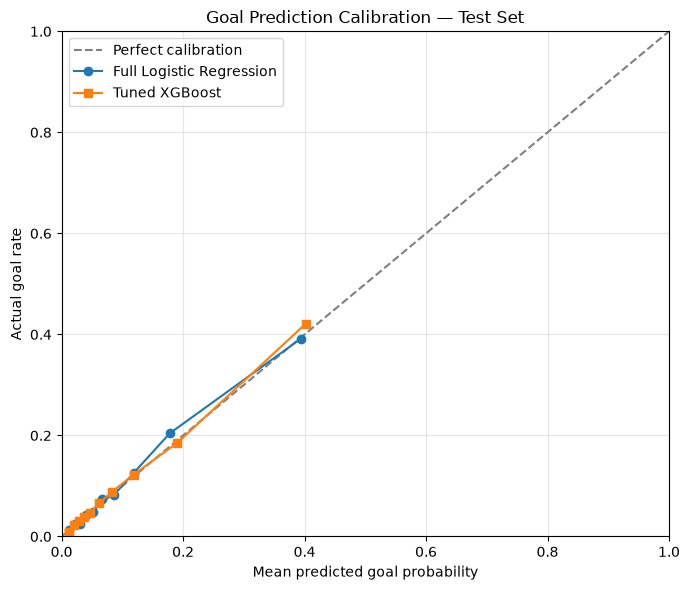

Saved to: ..\outputs\goal_calibration.png
Logistic regression bins: 10
XGBoost bins: 10


In [43]:
import matplotlib.pyplot as plt

LogregCalibration = calibration(
    FinalYTest,
    FullFinalTestPredictions,
    bins=10
)

XGBCalibration = calibration(
    FinalYTest,
    FinalTestPredictions,
    bins=10
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Perfect calibration"
)

plt.plot(
    LogregCalibration["predicted"],
    LogregCalibration["actual"],
    marker="o",
    label="Full Logistic Regression"
)

plt.plot(
    XGBCalibration["predicted"],
    XGBCalibration["actual"],
    marker="s",
    label="Tuned XGBoost"
)

plt.xlabel("Mean predicted goal probability")
plt.ylabel("Actual goal rate")
plt.title("Goal Prediction Calibration — Test Set")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OutputFolder / "goal_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", OutputFolder / "goal_calibration.png")
print("Logistic regression bins:", len(LogregCalibration))
print("XGBoost bins:", len(XGBCalibration))

In [44]:
TrainMatches = FinalTrainShots["match_id"].unique()

LearningSizes = [0.05, 0.10, 0.25, 0.50, 1.00]

print("Total training matches:", len(TrainMatches))

for Fraction in LearningSizes:
    MatchCount = max(1, round(len(TrainMatches) * Fraction))
    print(f"{Fraction:.0%} of matches: {MatchCount}")

Total training matches: 2998
5% of matches: 150
10% of matches: 300
25% of matches: 750
50% of matches: 1499
100% of matches: 2998


In [45]:
RandomGenerator = np.random.default_rng(42)

ShuffledMatches = RandomGenerator.permutation(TrainMatches)

LearningSubsets = {}

for Fraction in LearningSizes:
    MatchCount = max(1, round(len(ShuffledMatches) * Fraction))

    SelectedMatches = ShuffledMatches[:MatchCount]

    LearningSubsets[Fraction] = FinalTrainShots[
        FinalTrainShots["match_id"].isin(SelectedMatches)
    ]

    print(
        f"{Fraction:.0%} | "
        f"Matches: {MatchCount} | "
        f"Shots: {len(LearningSubsets[Fraction])} | "
        f"Goals: {LearningSubsets[Fraction]['goal'].sum()}"
    )

5% | Matches: 150 | Shots: 3739 | Goals: 403
10% | Matches: 300 | Shots: 7432 | Goals: 785
25% | Matches: 750 | Shots: 18789 | Goals: 1898
50% | Matches: 1499 | Shots: 37556 | Goals: 3842
100% | Matches: 2998 | Shots: 74944 | Goals: 7672


In [46]:
LearningResults = []

for Fraction in LearningSizes:
    Subset = LearningSubsets[Fraction]

    SubsetMedians = Subset[AllFeatures].median()

    SubsetXTrain = Subset[AllFeatures].fillna(SubsetMedians).to_numpy(dtype=float)
    SubsetXTest = FinalTestShots[AllFeatures].fillna(SubsetMedians).to_numpy(dtype=float)

    SubsetYTrain = Subset["goal"].to_numpy(dtype=int)

    LearningModel = XGBClassifier(
        n_estimators=400,
        max_depth=BestDepth,
        min_child_weight=BestChildWeight,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    LearningModel.fit(SubsetXTrain, SubsetYTrain)

    SubsetTrainPredictions = LearningModel.predict_proba(SubsetXTrain)[:, 1]
    SubsetTestPredictions = LearningModel.predict_proba(SubsetXTest)[:, 1]

    TrainAUC = roc_auc_score(SubsetYTrain, SubsetTrainPredictions)
    TestAUC = roc_auc_score(FinalYTest, SubsetTestPredictions)

    LearningResults.append({
        "trainingPercent": int(Fraction * 100),
        "matches": Subset["match_id"].nunique(),
        "shots": len(Subset),
        "trainAuc": TrainAUC,
        "testAuc": TestAUC
    })

    print(
        f"{Fraction:.0%} | "
        f"Train AUC: {TrainAUC:.4f} | "
        f"Test AUC: {TestAUC:.4f}"
    )

LearningResults = pd.DataFrame(LearningResults)

print("\nLearning curve results:")
print(LearningResults.round(4).to_string(index=False))

5% | Train AUC: 0.9184 | Test AUC: 0.7733
10% | Train AUC: 0.8813 | Test AUC: 0.7806
25% | Train AUC: 0.8495 | Test AUC: 0.7917
50% | Train AUC: 0.8348 | Test AUC: 0.7962
100% | Train AUC: 0.8242 | Test AUC: 0.8018

Learning curve results:
 trainingPercent  matches  shots  trainAuc  testAuc
               5      150   3739    0.9184   0.7733
              10      300   7432    0.8813   0.7806
              25      750  18789    0.8495   0.7917
              50     1499  37556    0.8348   0.7962
             100     2998  74944    0.8242   0.8018


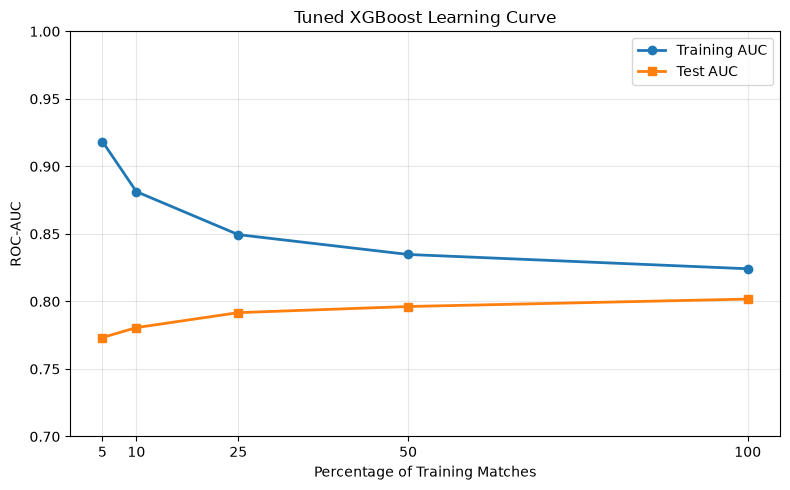

Saved to: ..\outputs\goal_learning_curve.png
Data points: 5
File exists: True


In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    LearningResults["trainingPercent"],
    LearningResults["trainAuc"],
    marker="o",
    linewidth=2,
    label="Training AUC"
)

plt.plot(
    LearningResults["trainingPercent"],
    LearningResults["testAuc"],
    marker="s",
    linewidth=2,
    label="Test AUC"
)

plt.xlabel("Percentage of Training Matches")
plt.ylabel("ROC-AUC")
plt.title("Tuned XGBoost Learning Curve")
plt.xticks(LearningResults["trainingPercent"])
plt.ylim(0.7, 1.0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OutputFolder / "goal_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", OutputFolder / "goal_learning_curve.png")
print("Data points:", len(LearningResults))
print(
    "File exists:",
    (OutputFolder / "goal_learning_curve.png").exists()
)

In [48]:
for Fold in range(1, 6):
    FoldTrain = Shots[
        (Shots["test"] == False) & (Shots["fold"] != Fold)
    ]

    FoldValid = Shots[
        (Shots["test"] == False) & (Shots["fold"] == Fold)
    ]

    SharedMatches = len(
        set(FoldTrain["match_id"]) & set(FoldValid["match_id"])
    )

    print(
        f"Fold {Fold}:",
        f"Train={len(FoldTrain)},",
        f"Validation={len(FoldValid)},",
        f"Shared matches={SharedMatches}"
    )

Fold 1: Train=59897, Validation=15047, Shared matches=0
Fold 2: Train=59952, Validation=14992, Shared matches=0
Fold 3: Train=59888, Validation=15056, Shared matches=0
Fold 4: Train=60001, Validation=14943, Shared matches=0
Fold 5: Train=60038, Validation=14906, Shared matches=0


In [49]:
WeightsNoL2 = fitLogreg(FullFinalXTrain, FinalYTrain, l2=0)
WeightsL2 = fitLogreg(FullFinalXTrain, FinalYTrain, l2=100)

PredNoL2 = predictLogreg(WeightsNoL2, FullFinalXTest)
PredL2 = predictLogreg(WeightsL2, FullFinalXTest)

print("Without L2")
print("AUC:", round(roc_auc_score(FinalYTest, PredNoL2), 4))
print("Log loss:", round(log_loss(FinalYTest, PredNoL2), 4))

print("\nWith L2")
print("AUC:", round(roc_auc_score(FinalYTest, PredL2), 4))
print("Log loss:", round(log_loss(FinalYTest, PredL2), 4))

Without L2
AUC: 0.7926
Log loss: 0.2736

With L2
AUC: 0.7926
Log loss: 0.2736


# polynomil feats 

In [50]:
PolyTrain = FinalTrainShots[["distance", "angle"]].copy()
PolyTest = FinalTestShots[["distance", "angle"]].copy()

for Data in [PolyTrain, PolyTest]:
    Data["distance2"] = Data["distance"] ** 2
    Data["angle2"] = Data["angle"] ** 2
    Data["distance_angle"] = Data["distance"] * Data["angle"]

print(PolyTrain.head())
print("\nTraining shape:", PolyTrain.shape)
print("Test shape:", PolyTest.shape)

      distance     angle  distance2    angle2  distance_angle
908  28.809026  0.212949     829.96  0.045347        6.134839
909  20.032474  0.391820     401.30  0.153523        7.849132
910  10.683164  0.566393     114.13  0.320801        6.050868
911   8.202439  0.735481      67.28  0.540932        6.032735
912   7.615773  0.898833      58.00  0.807901        6.845309

Training shape: (74944, 5)
Test shape: (24802, 5)


In [51]:
PolyMean, PolyStd = fitScaling(PolyTrain.to_numpy(dtype=float))

PolyXTrain = applyScaling(
    PolyTrain.to_numpy(dtype=float), PolyMean, PolyStd
)

PolyXTest = applyScaling(
    PolyTest.to_numpy(dtype=float), PolyMean, PolyStd
)

PolyWeights = fitLogreg(PolyXTrain, FinalYTrain)

PolyPredictions = predictLogreg(PolyWeights, PolyXTest)

print("Basic logistic regression:")
print("AUC:", round(BasicResults["testAuc"], 4))
print("Log loss:", round(BasicResults["testLogloss"], 4))

print("\nPolynomial logistic regression:")
print("AUC:", round(roc_auc_score(FinalYTest, PolyPredictions), 4))
print("Log loss:", round(log_loss(FinalYTest, PolyPredictions), 4))

Basic logistic regression:
AUC: 0.7249
Log loss: 0.3007

Polynomial logistic regression:
AUC: 0.7252
Log loss: 0.3012


In [52]:
CostX = BasicXTrain
CostY = FinalYTrain

print("Training rows:", CostX.shape[0])
print("Features:", CostX.shape[1])
print("Learning rates:", [0.01, 0.1, 1.0])

Training rows: 74944
Features: 2
Learning rates: [0.01, 0.1, 1.0]


In [53]:
from src.logreg import sigmoid
CostHistory = {}

for Rate in [0.01, 0.1, 1.0]:
    X = np.column_stack([np.ones(len(CostX)), CostX])
    Y = CostY

    Weights = np.zeros(X.shape[1])
    Costs = []

    for Step in range(2000):
        Predictions = sigmoid(X @ Weights)

        Cost = -np.mean(
            Y * np.log(np.clip(Predictions, 1e-15, 1)) +
            (1 - Y) * np.log(np.clip(1 - Predictions, 1e-15, 1))
        )

        Costs.append(Cost)

        Gradient = (X.T @ (Predictions - Y)) / len(Y)
        Weights -= Rate * Gradient

    CostHistory[Rate] = Costs

    print(
        "Rate:", Rate,
        "| Starting cost:", round(Costs[0], 4),
        "| Final cost:", round(Costs[-1], 4)
    )

Rate: 0.01 | Starting cost: 0.6931 | Final cost: 0.2988
Rate: 0.1 | Starting cost: 0.6931 | Final cost: 0.2933
Rate: 1.0 | Starting cost: 0.6931 | Final cost: 0.2933


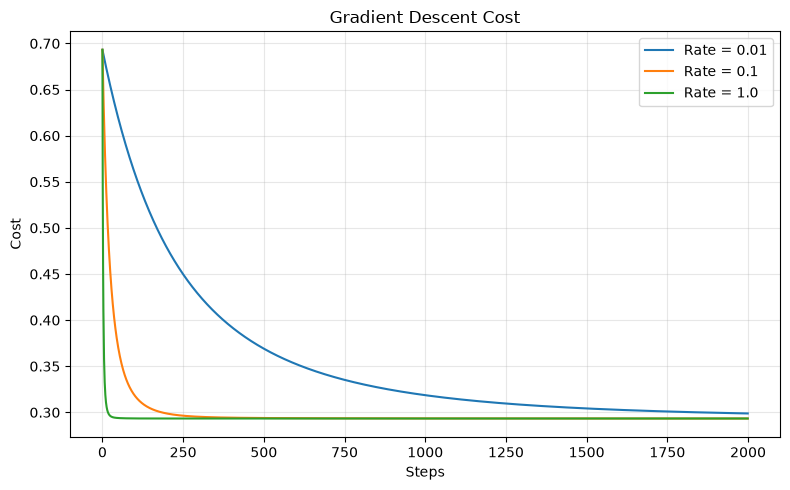

In [54]:
plt.figure(figsize=(8, 5))

for Rate in [0.01, 0.1, 1.0]:
    plt.plot(CostHistory[Rate], label=f"Rate = {Rate}")

plt.xlabel("Steps")
plt.ylabel("Cost")
plt.title("Gradient Descent Cost")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
LBFGSModel = LogisticRegression(
    solver="lbfgs",
    max_iter=2000,
    C=np.inf
)

LBFGSModel.fit(BasicXTrain, FinalYTrain)

LBFGSPredictions = LBFGSModel.predict_proba(BasicXTest)[:, 1]

print("Gradient Descent")
print("AUC:", round(roc_auc_score(FinalYTest, BasicTestPredictions), 4))
print("Log loss:", round(log_loss(FinalYTest, BasicTestPredictions), 4))

print("\nL-BFGS")
print("AUC:", round(roc_auc_score(FinalYTest, LBFGSPredictions), 4))
print("Log loss:", round(log_loss(FinalYTest, LBFGSPredictions), 4))

Gradient Descent
AUC: 0.7249
Log loss: 0.3007

L-BFGS
AUC: 0.7248
Log loss: 0.3007


In [56]:
print(
    Shots[["x", "y", "distance", "angle"]]
    .head(10)
    .to_string(index=False)
)

print("\nX range:", Shots["x"].min(), Shots["x"].max())
print("Y range:", Shots["y"].min(), Shots["y"].max())

    x    y  distance    angle
107.0 53.4 18.669762 0.303090
 96.5 39.9 23.500213 0.337188
 88.2 45.5 32.272124 0.243168
 98.5 49.2 23.385679 0.313313
111.2 37.8  9.070832 0.815532
107.5 39.1 12.532358 0.616686
 96.5 33.7 24.329817 0.315518
112.4 31.4 11.476933 0.483765
109.3 36.4 11.289376 0.654958
105.8 35.8 14.808106 0.509601

X range: 30.2 120.5
Y range: 0.2 79.8


In [57]:
import src.pitch as Pitch

print("Available pitch functions:")
print([Name for Name in dir(Pitch) if not Name.startswith("_")])

Available pitch functions:
['GOAL_X', 'GOAL_Y', 'LEFT_POST_Y', 'RIGHT_POST_Y', 'distanceToGoal', 'goalAngle', 'inShotCone', 'np', 'sideOfLine']


In [58]:
print("Distance:", inspect.signature(Pitch.distanceToGoal))
print("Angle:", inspect.signature(Pitch.goalAngle))

print("\nDistance function:")
print(inspect.getsource(Pitch.distanceToGoal))

print("\nAngle function:")
print(inspect.getsource(Pitch.goalAngle))

Distance: (x, y)
Angle: (x, y)

Distance function:
def distanceToGoal(x, y):
    return np.sqrt((GOAL_X - x) ** 2 + (GOAL_Y - y) ** 2)


Angle function:
def goalAngle(x, y):
    toLeftPost = np.arctan2(LEFT_POST_Y - y, GOAL_X - x)
    toRightPost = np.arctan2(RIGHT_POST_Y - y, GOAL_X - x)
    return np.abs(toRightPost - toLeftPost)



In [59]:
GridX, GridY = np.meshgrid(
    np.linspace(60, 120, 121),
    np.linspace(0, 80, 161)
)

GridDistance = Pitch.distanceToGoal(GridX, GridY)
GridAngle = Pitch.goalAngle(GridX, GridY)

GridFeatures = np.column_stack([
    GridDistance.ravel(),
    GridAngle.ravel()
])

GridScaled = applyScaling(GridFeatures, BasicMean, BasicStd)

GridPredictions = predictLogreg(BasicWeights, GridScaled)
GridProbabilities = GridPredictions.reshape(GridX.shape)

print("Grid shape:", GridX.shape)
print("Minimum probability:", round(GridProbabilities.min(), 4))
print("Maximum probability:", round(GridProbabilities.max(), 4))
print("Missing predictions:", np.isnan(GridProbabilities).sum())

Grid shape: (161, 121)
Minimum probability: 0.0013
Maximum probability: 0.8958
Missing predictions: 0


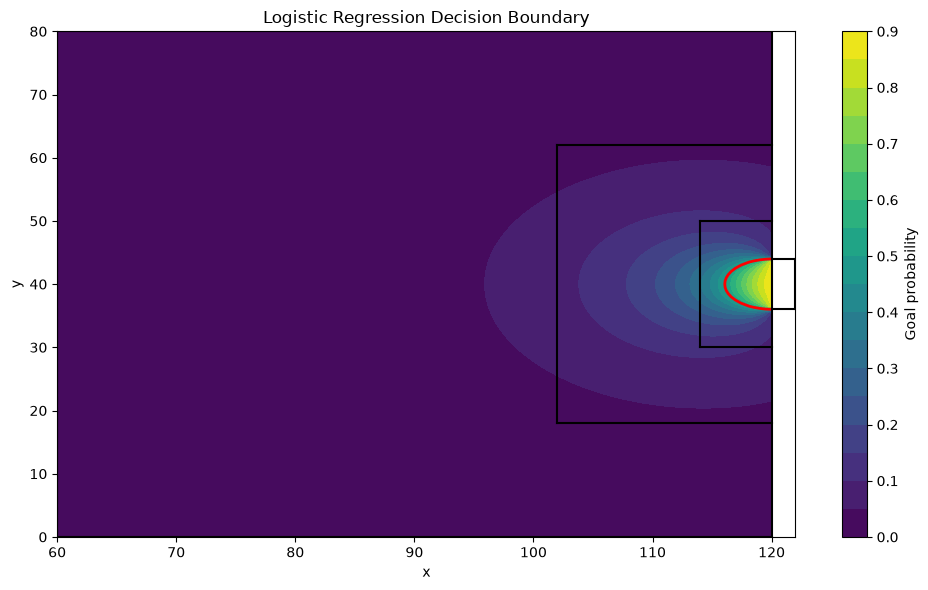

In [60]:
plt.figure(figsize=(10, 6))

ProbabilityPlot = plt.contourf(
    GridX,
    GridY,
    GridProbabilities,
    levels=20,
    cmap="viridis"
)

Boundary = plt.contour(
    GridX,
    GridY,
    GridProbabilities,
    levels=[0.5],
    colors="red",
    linewidths=2
)

plt.colorbar(ProbabilityPlot, label="Goal probability")

plt.plot([60, 120], [0, 0], color="black")
plt.plot([60, 120], [80, 80], color="black")
plt.plot([60, 60], [0, 80], color="black")
plt.plot([120, 120], [0, 80], color="black")

plt.plot([60, 60], [0, 80], color="black", linestyle="--", alpha=0.5)

plt.plot([102, 120], [18, 18], color="black")
plt.plot([102, 102], [18, 62], color="black")
plt.plot([102, 120], [62, 62], color="black")

plt.plot([114, 120], [30, 30], color="black")
plt.plot([114, 114], [30, 50], color="black")
plt.plot([114, 120], [50, 50], color="black")

plt.plot([120, 122], [36, 36], color="black")
plt.plot([122, 122], [36, 44], color="black")
plt.plot([120, 122], [44, 44], color="black")

plt.xlim(60, 122)
plt.ylim(0, 80)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Logistic Regression Decision Boundary")
plt.tight_layout()
plt.show()

In [61]:
from sklearn.linear_model import LinearRegression

LinearModel = LinearRegression()
LinearModel.fit(BasicXTrain, FinalYTrain)

LinearTrainPredictions = LinearModel.predict(BasicXTrain)
LinearTestPredictions = LinearModel.predict(BasicXTest)

print("Training predictions:", len(LinearTrainPredictions))
print("Test predictions:", len(LinearTestPredictions))

print("Minimum prediction:", round(LinearTestPredictions.min(), 4))
print("Maximum prediction:", round(LinearTestPredictions.max(), 4))

print("Below zero:", (LinearTestPredictions < 0).sum())
print("Above one:", (LinearTestPredictions > 1).sum())

Training predictions: 74944
Test predictions: 24802
Minimum prediction: -0.1071
Maximum prediction: 0.83
Below zero: 470
Above one: 0


In [62]:
LinearOOF = pd.Series(np.nan, index=Shots.index)

for Fold in range(1, 6):
    FoldTrain = Shots[(~Shots["test"]) & (Shots["fold"] != Fold)]
    FoldValid = Shots[(~Shots["test"]) & (Shots["fold"] == Fold)]

    FoldXTrain = FoldTrain[BasicFeatures].to_numpy(dtype=float)
    FoldXValid = FoldValid[BasicFeatures].to_numpy(dtype=float)

    FoldYTrain = FoldTrain["goal"].to_numpy(dtype=int)

    FoldModel = LinearRegression()
    FoldModel.fit(FoldXTrain, FoldYTrain)

    LinearOOF.loc[FoldValid.index] = FoldModel.predict(FoldXValid)

    print("Fold:", Fold, "| Predictions:", len(FoldXValid))

print("Total OOF predictions:", LinearOOF.notna().sum())
print("Missing training predictions:", LinearOOF.loc[TrainMask].isna().sum())

Fold: 1 | Predictions: 15047
Fold: 2 | Predictions: 14992
Fold: 3 | Predictions: 15056
Fold: 4 | Predictions: 14943
Fold: 5 | Predictions: 14906
Total OOF predictions: 74944
Missing training predictions: 0


In [63]:
LinearTrainClipped = np.clip(LinearTrainPredictions, 1e-6, 1 - 1e-6)
LinearValidClipped = np.clip(LinearOOF.loc[TrainMask].to_numpy(), 1e-6, 1 - 1e-6)
LinearTestClipped = np.clip(LinearTestPredictions, 1e-6, 1 - 1e-6)

LinearResults = resultsRow(
    "Linear Probability Model",
    FinalYTrain,
    LinearTrainClipped,
    OOFActual,
    LinearValidClipped,
    FinalYTest,
    LinearTestClipped
)

print(LinearResults)

{'model': 'Linear Probability Model', 'trainAuc': 0.7411114878002627, 'trainBrier': 0.08375822933178734, 'trainLogloss': 0.30074191242152365, 'validationAuc': 0.7409197101760229, 'validationBrier': 0.08377088376689354, 'validationLogloss': 0.30092047618506446, 'testAuc': 0.7236756709420836, 'testBrier': 0.0854300600224171, 'testLogloss': 0.3144122494663971}


In [64]:
GoalResults = pd.concat([
    GoalResults[GoalResults["model"] != "Linear Probability Model"],
    pd.DataFrame([LinearResults])
], ignore_index=True)

GoalResults.to_csv(OutputFolder / "goal_results.csv", index=False)

print(GoalResults[["model", "testAuc", "testLogloss"]].round(4).to_string(index=False))
print("\nModels:", len(GoalResults))
print("Missing values:", GoalResults.isna().sum().sum())

                      model  testAuc  testLogloss
                      Floor   0.5000       0.3322
Logistic Regression (Basic)   0.7249       0.3007
 Logistic Regression (Full)   0.7926       0.2736
              Tuned XGBoost   0.8018       0.2672
            Overfit XGBoost   0.7720       0.3063
     Class-weighted XGBoost   0.8007       0.5165
   Linear Probability Model   0.7237       0.3144

Models: 7
Missing values: 0
